# Контрольная работа

### Задания: Linux (п.2), Вычислительная (п.5), Файлы (п.1)

---
## Задание 1. Команды Linux (пункт 2)

### Условие

Список всех выполняемых процессов переписать в файл `Task_1`. Создать в каталоге `sandbox` каталог `sandbox-2`, переместить туда файлы `Task_2`, `Task_3`. Переписать содержимое файла `/bin/ls` в файл `Task_2`, переименовав его в `myls`, установить права доступа `r-xr--r--`. Добавить в файл `Task_3` информацию о ядре системы.

### Команды

```bash
cd sandbox
touch Task_1 Task_2 Task_3
ps aux > Task_1
mkdir -p sandbox-2
mv Task_2 Task_3 sandbox-2/
cp /bin/ls sandbox-2/Task_2
cd sandbox-2 && mv Task_2 myls && chmod 544 myls
uname -a >> Task_3
```

In [ ]:
!cd sandbox && ls -la && echo '--- sandbox-2 ---' && ls -la sandbox-2/ && echo '--- Task_3 ---' && cat sandbox-2/Task_3

### Результат

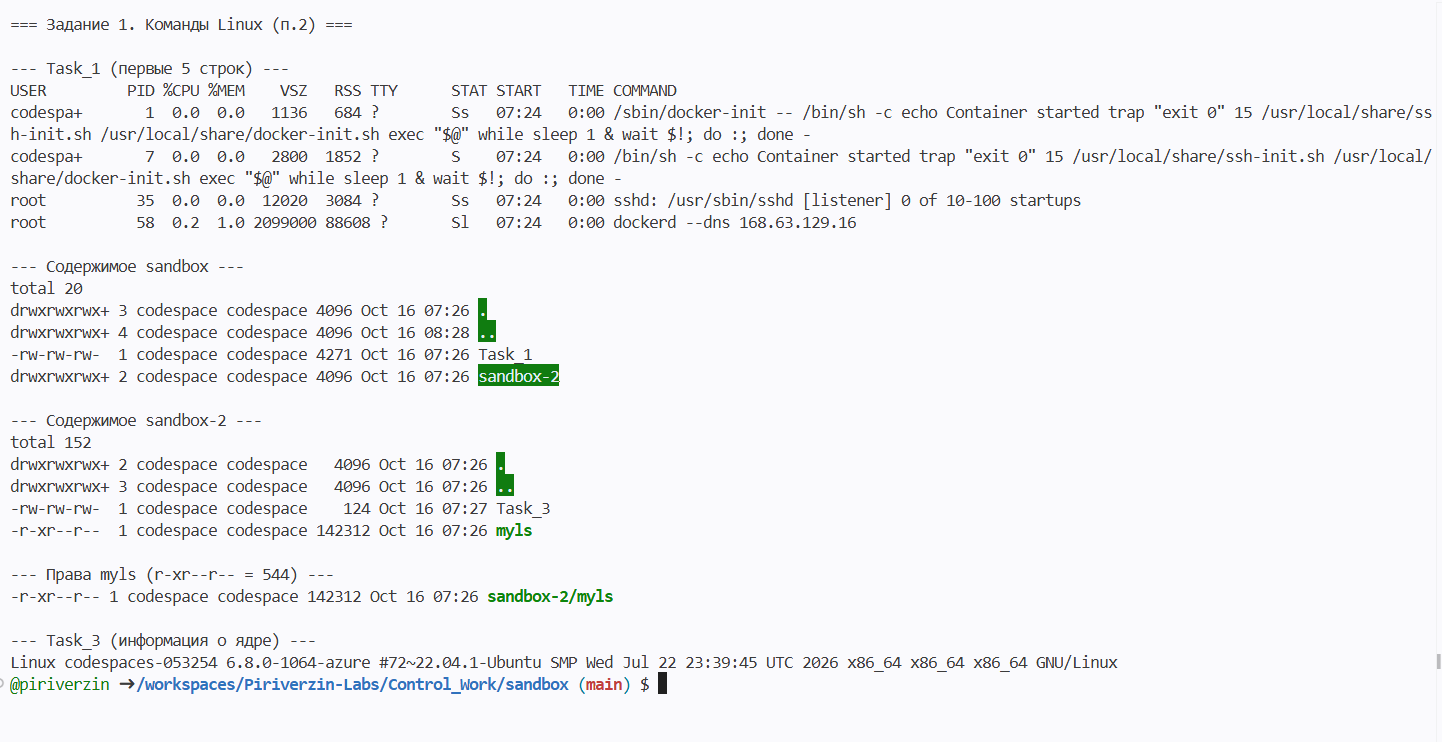

---
## Задание 2. Вычислительная задача (пункт 5)

### Условие

Вычислить `S = Σ_{k=1}^{n} k · first_digit(k)`, где `first_digit(k)` — первая значащая цифра числа `k`.

### Исходный код (first_digit.asm)

```asm
format ELF executable 3
entry start
segment readable executable
start:
    mov ebp, esp
    mov eax, [ebp]
    cmp eax, 2
    jne .usage
    mov esi, [ebp + 8]
    call parse_int
    mov [n], eax
    xor ebx, ebx
    mov ecx, 1
.loop:
    cmp ecx, [n]
    jg .done
    push ebx
    push ecx
    mov eax, ecx
    call first_digit
    pop ecx
    pop ebx
    mov edx, ecx
    imul edx, eax
    add ebx, edx
    inc ecx
    jmp .loop
.done:
    mov eax, ebx
    call print_num
    mov eax, 4
    mov ebx, 1
    mov ecx, nl
    mov edx, 1
    int 0x80
    mov eax, 1
    xor ebx, ebx
    int 0x80
first_digit:
    mov ebx, 10
.fd_loop:
    cmp eax, 10
    jl .fd_done
    xor edx, edx
    div ebx
    jmp .fd_loop
.fd_done:
    ret
```

In [ ]:
!fasm first_digit.asm first_digit
!chmod +x first_digit
!for n in 1 5 9 10 15 20 100; do echo -n "n=$$n -> "; ./first_digit $$n; done

### Результат
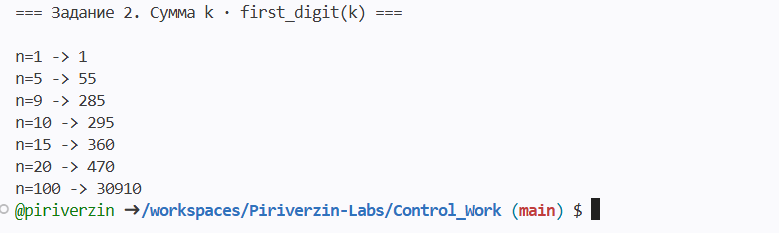

---
## Задание 3. Работа с файлами (пункт 1)

### Условие

Программа принимает два параметра командной строки: имя каталога и число `n`. Создаёт в этом каталоге `n` файлов со случайными именами.

### Исходный код (make_files.asm)

```asm
format ELF executable 3
entry start
segment readable executable
start:
    mov ebp, esp
    mov eax, [ebp]
    cmp eax, 3
    jne .usage
    mov eax, 12
    mov ebx, [ebp + 8]
    int 0x80
    test eax, eax
    js .chdir_error
    mov esi, [ebp + 12]
    call parse_int
    mov [n], eax
    mov eax, 20
    int 0x80
    mov [seed], eax
    mov eax, 13
    xor ebx, ebx
    int 0x80
    xor [seed], eax
    xor edi, edi
.create_loop:
    cmp edi, [n]
    jge .done
    call gen_random_name
    mov eax, 8
    mov ebx, filename
    mov ecx, 644o
    int 0x80
    inc edi
    jmp .create_loop
.done:
    mov eax, 1
    xor ebx, ebx
    int 0x80
```

In [ ]:
!fasm make_files.asm make_files
!chmod +x make_files
!mkdir -p testdir
!rm -f testdir/*
!echo '--- До ---'
!ls -la testdir/
!./make_files testdir 7
!echo '--- После ---'
!ls -la testdir/

### Результат

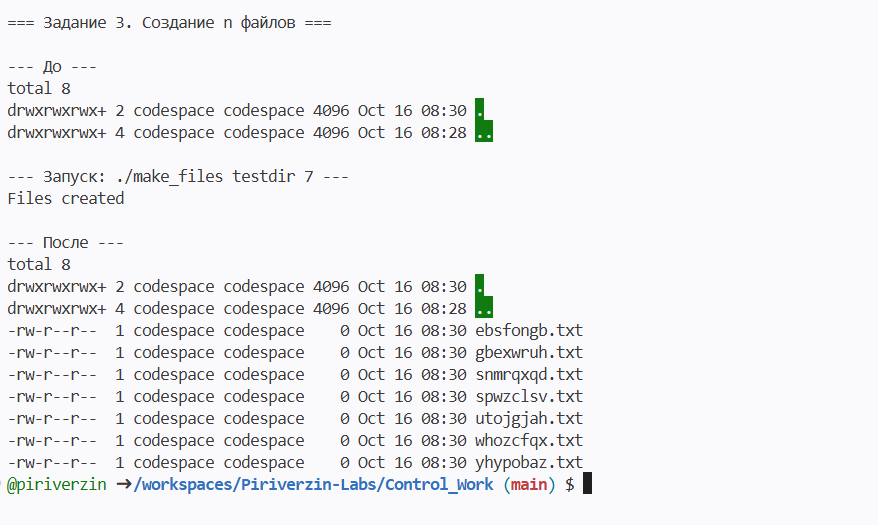

---
## Вывод

1. Освоены команды Linux для работы с процессами, файлами, правами доступа.
2. Реализована программа на FASM для вычисления суммы `Σ k · first_digit(k)`.
3. Реализована программа на FASM для создания `n` файлов со случайными именами в указанном каталоге.